# Day 3: Improve the CNN and Understand What It Learned
**Deep Learning Internship, Phase 2 (CNNs): main project**

Goals: (1) add **batch normalization** and **dropout** to the CNN, (2) train with Adam and track train/validation curves, (3) evaluate **once** on the test set with a confusion matrix, (4) look at misclassified images, (5) visualise the first-layer filters and feature maps.

> Colab: Runtime > Change runtime type > **T4 GPU**. On a CPU, set `EPOCHS = 3` first.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cpu


## 1. Data (same split as Day 2: 55,000 train / 5,000 validation / 10,000 test)

In [2]:
MEAN, STD = 0.2860, 0.3530
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])

full_train = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)
train_set, val_set = random_split(full_train, [55000, 5000],
                                  generator=torch.Generator().manual_seed(42))

BATCH_SIZE = 128
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE)

classes = full_train.classes
print("train / val / test:", len(train_set), len(val_set), len(test_set))
print(classes)

train / val / test: 55000 5000 10000
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## 2. CNN with batch normalization and dropout
- **BatchNorm2d** normalises each layer's outputs per channel, so training is faster and more stable.
- **Dropout** randomly switches off neurons while training (only in the classifier part) to reduce overfitting.
- `model.train()` enables dropout and uses batch statistics; `model.eval()` turns dropout off and uses the running statistics. Forgetting `model.eval()` gives wrong results.

Shape: `1x28x28 -> 32x28x28 -> 32x14x14 -> 64x14x14 -> 64x7x7 -> 3136 -> 128 -> 10`

In [3]:
class FashionCNN(nn.Module):
    def __init__(self, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = FashionCNN().to(device)

# Track the tensor shape after every layer
x = torch.randn(1, 1, 28, 28).to(device)
model.eval()
with torch.no_grad():
    for layer in list(model.features) + list(model.classifier):
        x = layer(x)
        print(f"{layer.__class__.__name__:<12} -> {tuple(x.shape)}")

print("\nParameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Conv2d       -> (1, 32, 28, 28)
BatchNorm2d  -> (1, 32, 28, 28)
ReLU         -> (1, 32, 28, 28)
MaxPool2d    -> (1, 32, 14, 14)
Conv2d       -> (1, 64, 14, 14)
BatchNorm2d  -> (1, 64, 14, 14)
ReLU         -> (1, 64, 14, 14)
MaxPool2d    -> (1, 64, 7, 7)
Flatten      -> (1, 3136)
Linear       -> (1, 128)
ReLU         -> (1, 128)
Dropout      -> (1, 128)
Linear       -> (1, 10)

Parameters: 421,834


## 3. Training loop (Adam), saving the best model by validation accuracy

In [4]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total


EPOCHS = 10          # use 3 on a CPU first
LR = 1e-3

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_state = 0.0, None

start = time.time()
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
    va_loss, va_acc = run_epoch(model, val_loader, criterion)
    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} "
          f"| val loss {va_loss:.4f} acc {va_acc:.4f}")
print(f"\nTraining time: {time.time() - start:.1f}s | best val acc: {best_val_acc:.4f}")

Epoch  1/10 | train loss 0.5191 acc 0.8152 | val loss 0.3242 acc 0.8822
Epoch  2/10 | train loss 0.3544 acc 0.8728 | val loss 0.2761 acc 0.9010
Epoch  3/10 | train loss 0.3117 acc 0.8886 | val loss 0.2663 acc 0.9010
Epoch  4/10 | train loss 0.2822 acc 0.8968 | val loss 0.2405 acc 0.9104
Epoch  5/10 | train loss 0.2626 acc 0.9051 | val loss 0.2452 acc 0.9088
Epoch  6/10 | train loss 0.2451 acc 0.9096 | val loss 0.2391 acc 0.9140
Epoch  7/10 | train loss 0.2309 acc 0.9153 | val loss 0.2365 acc 0.9124
Epoch  8/10 | train loss 0.2164 acc 0.9197 | val loss 0.2437 acc 0.9092
Epoch  9/10 | train loss 0.2043 acc 0.9240 | val loss 0.2270 acc 0.9186
Epoch 10/10 | train loss 0.1925 acc 0.9288 | val loss 0.2426 acc 0.9156

Training time: 1195.1s | best val acc: 0.9186


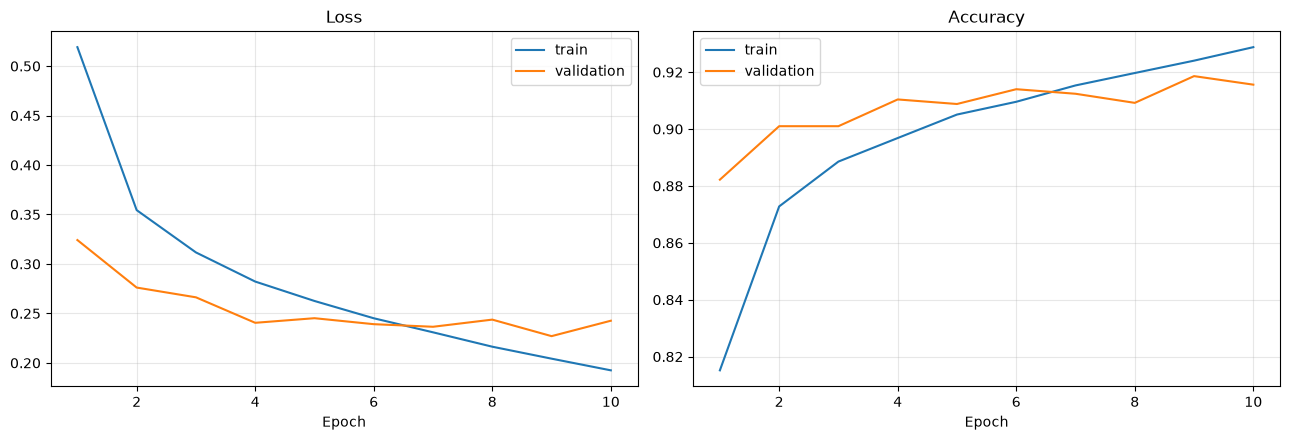

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ep = range(1, EPOCHS + 1)
axes[0].plot(ep, history["train_loss"], label="train"); axes[0].plot(ep, history["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[1].plot(ep, history["train_acc"], label="train"); axes[1].plot(ep, history["val_acc"], label="validation")
axes[1].set_title("Accuracy")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Final test evaluation (done once)
We load the best weights (by validation accuracy) and evaluate on the test set a single time.

In [6]:
model.load_state_dict(best_state)
model.eval()

all_preds, all_targets = [], []
wrong_imgs, wrong_true, wrong_pred = [], [], []

with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        preds = out.argmax(1).cpu()
        all_preds.append(preds); all_targets.append(y)
        mask = preds != y
        if mask.any() and len(wrong_imgs) < 16:
            for img, t, p in zip(x[mask], y[mask], preds[mask]):
                if len(wrong_imgs) < 16:
                    wrong_imgs.append(img); wrong_true.append(t.item()); wrong_pred.append(p.item())

all_preds = torch.cat(all_preds).numpy()
all_targets = torch.cat(all_targets).numpy()
test_acc = (all_preds == all_targets).mean()
print(f"TEST ACCURACY: {test_acc:.4f}")

TEST ACCURACY: 0.9166


## 5. Confusion matrix and per-class accuracy

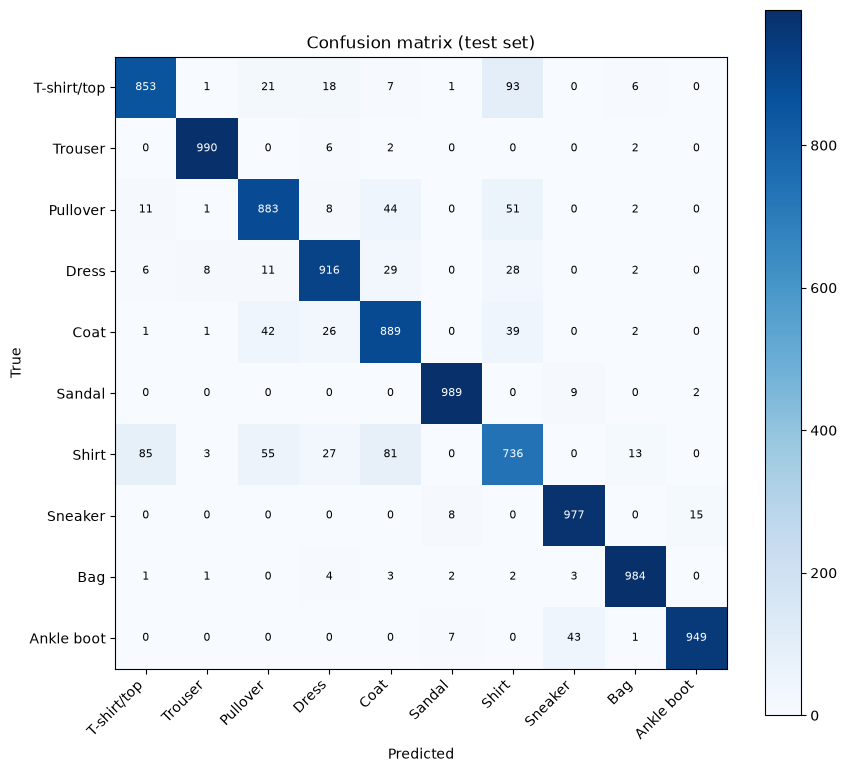

Per-class accuracy:
  T-shirt/top  0.853
  Trouser      0.990
  Pullover     0.883
  Dress        0.916
  Coat         0.889
  Sandal       0.989
  Shirt        0.736
  Sneaker      0.977
  Bag          0.984
  Ankle boot   0.949

Most confused pairs (true -> predicted):
  T-shirt/top -> Shirt: 93 images
  Shirt -> T-shirt/top: 85 images
  Shirt -> Coat: 81 images
  Shirt -> Pullover: 55 images
  Pullover -> Shirt: 51 images


In [7]:
n = len(classes)
cm = np.zeros((n, n), dtype=int)
np.add.at(cm, (all_targets, all_preds), 1)      # rows = true class, columns = predicted class

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(n)); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(n)); ax.set_yticklabels(classes)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (test set)")
for i in range(n):
    for j in range(n):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.show()

print("Per-class accuracy:")
for i, c in enumerate(classes):
    print(f"  {c:<12} {cm[i, i] / cm[i].sum():.3f}")

# Most confused pairs
off = cm.copy()
np.fill_diagonal(off, 0)
print("\nMost confused pairs (true -> predicted):")
for idx in np.argsort(off, axis=None)[::-1][:5]:
    i, j = divmod(idx, n)
    print(f"  {classes[i]} -> {classes[j]}: {off[i, j]} images")

## 6. Misclassified images

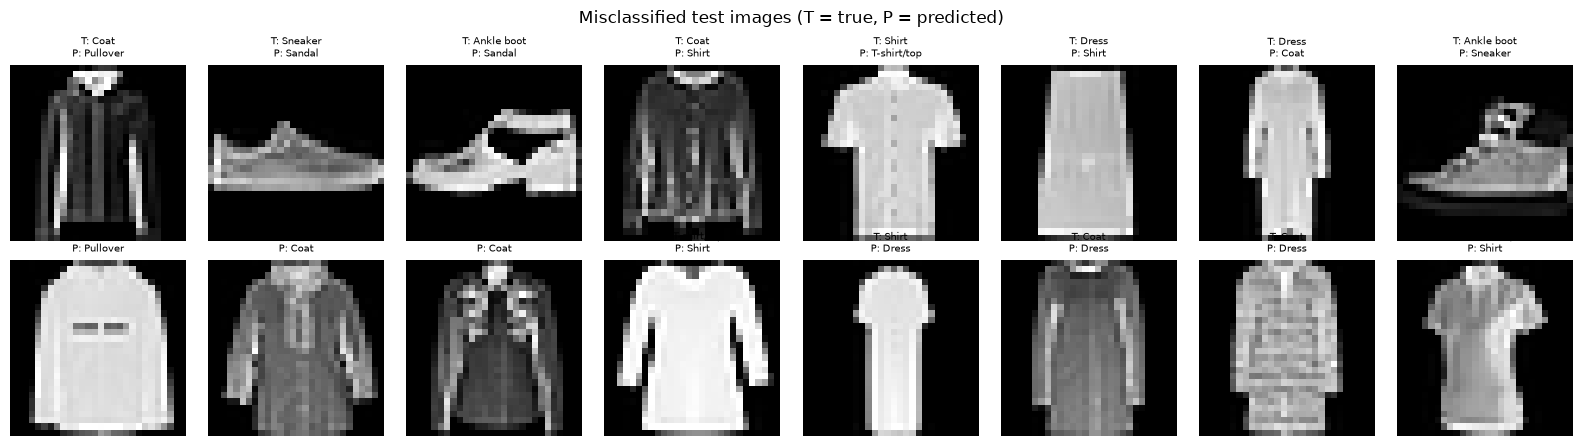

In [8]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, img, t, p in zip(axes.ravel(), wrong_imgs, wrong_true, wrong_pred):
    ax.imshow(img.squeeze() * STD + MEAN, cmap="gray")
    ax.set_title(f"T: {classes[t]}\nP: {classes[p]}", fontsize=7)
    ax.axis("off")
for ax in axes.ravel()[len(wrong_imgs):]:
    ax.axis("off")
plt.suptitle("Misclassified test images (T = true, P = predicted)")
plt.tight_layout()
plt.show()

## 7. Visualise what the CNN learned
**First-layer filters:** the 32 learned 3x3 kernels. **Feature maps:** what those filters produce for one image.
Compare with Day 1: the learned filters often look like edge and texture detectors.

first-layer filter tensor: (32, 1, 3, 3)


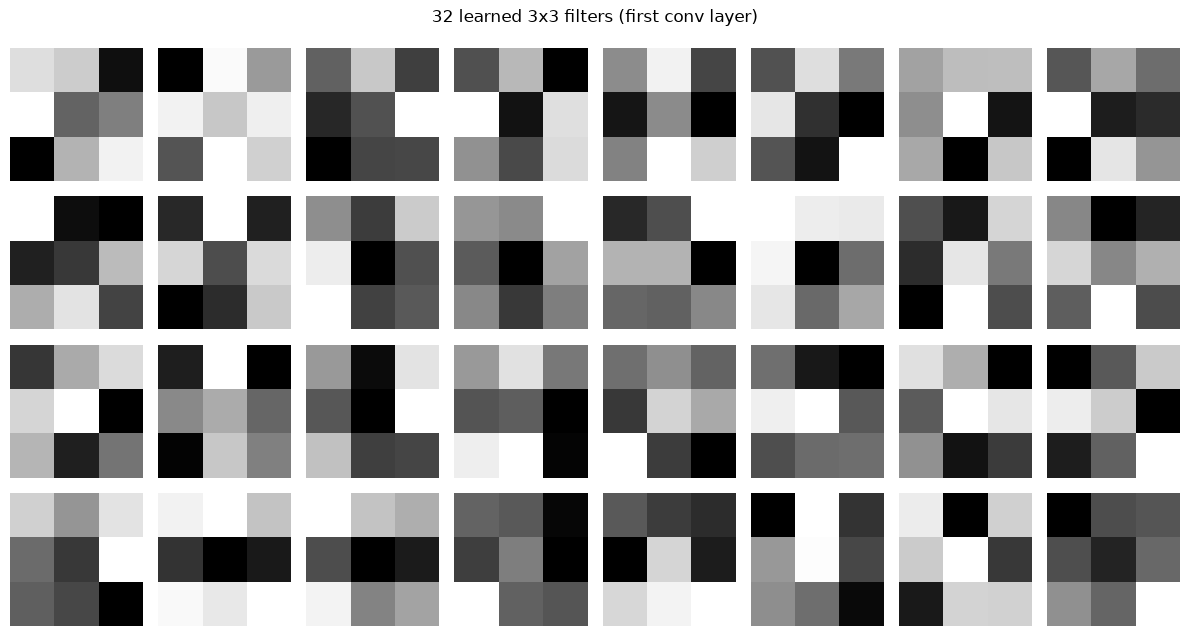

In [9]:
filters = model.features[0].weight.detach().cpu()      # shape [32, 1, 3, 3]
print("first-layer filter tensor:", tuple(filters.shape))

fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for ax, f in zip(axes.ravel(), filters):
    ax.imshow(f.squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("32 learned 3x3 filters (first conv layer)")
plt.tight_layout()
plt.show()

Image class: Ankle boot
feature maps: (32, 28, 28)


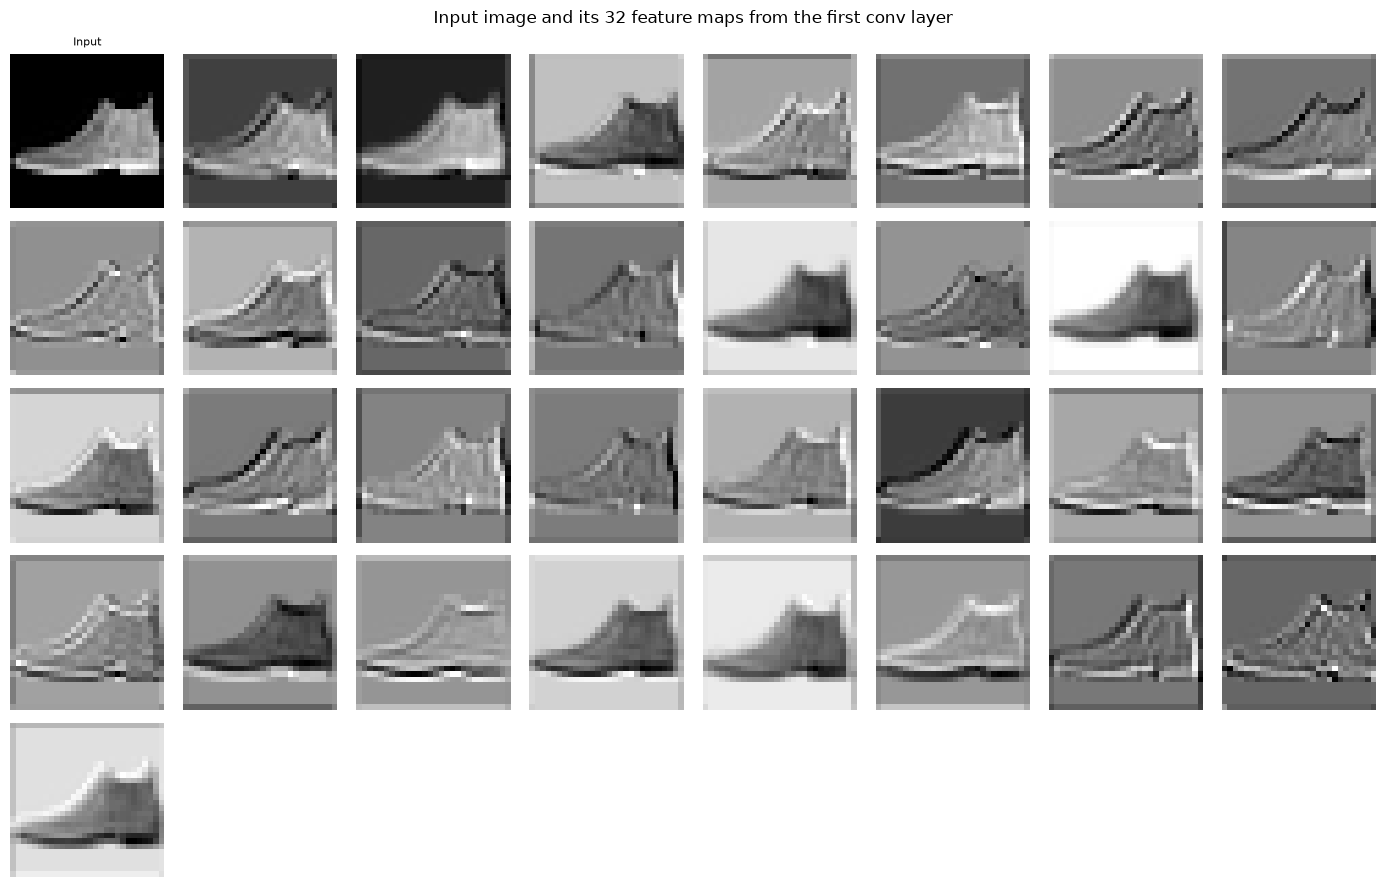

In [10]:
# Feature maps for one test image after the first conv block
img, label = test_set[0]
print("Image class:", classes[label])

model.eval()
with torch.no_grad():
    fmaps = model.features[0](img.unsqueeze(0).to(device)).squeeze(0).cpu()   # [32, 28, 28]
print("feature maps:", tuple(fmaps.shape))

fig, axes = plt.subplots(5, 8, figsize=(14, 9))
axes[0, 0].imshow(img.squeeze() * STD + MEAN, cmap="gray")
axes[0, 0].set_title("Input", fontsize=8)
for k, ax in enumerate(axes.ravel()[1:33]):
    ax.imshow(fmaps[k], cmap="gray")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Input image and its 32 feature maps from the first conv layer")
plt.tight_layout()
plt.show()

## Summary (rewrite in your own words)
- Batch norm normalises layer outputs, which makes training faster and more stable; dropout reduces overfitting by randomly switching neurons off during training only.
- `model.train()` vs `model.eval()` matters now, because batch norm and dropout behave differently in the two modes.
- Use the validation set to choose the model and the test set only once at the end.
- The confusion matrix shows *which* classes get mixed up (for example shirt, T-shirt/top, pullover and coat), which accuracy alone hides.
- The first-layer filters work as small edge and texture detectors, and the feature maps show what each one responds to.
- Next (Day 4): colour images, data augmentation and CIFAR-10.